# Module 3: Computer Vision -- Real Estate Room Classification
### Python Programming and AI -- Hochschule fur Wirtschaft und Umwelt (HfWU)

---

## Learning Objectives

By the end of this session, you will be able to:

1. Load a real-world image dataset from HuggingFace
2. Explore and visualize image data using matplotlib
3. Preprocess images for machine learning (resizing, normalisation, flattening)
4. Train a baseline image classifier using Logistic Regression
5. Train a simple CNN (Convolutional Neural Network)
6. Apply transfer learning using a pre-trained MobileNetV2 model
7. Evaluate and compare all three models using accuracy and confusion matrices
8. Package the workflow into a reusable sklearn Pipeline

---

## The Big Idea

When a property platform like ImmoScout24 or Zillow receives thousands of
new listings daily, each with 10-30 photos, those photos need to be
automatically sorted into categories: kitchen, bedroom, bathroom, living room,
exterior. No human team can label millions of images manually.

This is where Computer Vision comes in -- teaching machines to see and
classify images the way a human would, but at scale.

Today we build exactly that: a model that looks at a property photo and
predicts which room type it shows.

---

**Estimated Time:** 75-90 minutes  
**Dataset:** MIT Indoor Scene Recognition via HuggingFace, filtered to 6 room types (1,890 training and 279 test images)  
**Libraries:** datasets, numpy, sklearn, tensorflow/keras, matplotlib, plotly  

---

**New concept this module: Images as numbers**

A digital image is just a grid of numbers. A 224x224 colour photograph
is a 224 x 224 x 3 array (height x width x 3 colour channels: red, green, blue).
Each value is a number between 0 and 255 representing brightness.
Machine learning on images means finding patterns in these numbers.

---
## Step 1: Install and Import Libraries

| Library | Purpose |
|---|---|
| datasets | Load real-world image datasets from HuggingFace |
| numpy | Numerical operations on image arrays |
| sklearn | Logistic Regression, Pipeline, metrics |
| tensorflow/keras | Pre-trained MobileNetV2 for transfer learning |
| matplotlib | Display images inline |
| plotly | Interactive charts |
| PIL | Image resizing and manipulation |

In [3]:
!pip install datasets numpy scikit-learn tensorflow matplotlib plotly pillow --quiet
print("Libraries ready!")

Libraries ready!


In [4]:
import numpy as np
import warnings
warnings.filterwarnings('ignore')

import matplotlib.pyplot as plt
import plotly.express as px
import plotly.graph_objects as go

from PIL import Image
from datasets import load_dataset

from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
import joblib

print("All libraries imported successfully!")

All libraries imported successfully!


---
## Step 2: Load Real Property Images from HuggingFace

We use the MIT Indoor Scene Recognition dataset, available on HuggingFace.
The original dataset has 67 indoor scene categories. The HuggingFace version
used here provides 64 of them.

For our real estate use case, we keep 6 room types that appear in property listings.
Bedroom and bathroom are not available as categories in this version of the dataset,
so they are not included:

| Category | What it looks like |
|---|---|
| kitchen | Cabinets, stove, sink, countertop |
| livingroom | Sofa, TV, coffee table |
| dining_room | Table, chairs, often connected to kitchen |
| corridor | Hallway, doors, narrow space |
| office | Desk, computer, bookshelves |
| garage | Cars, tools, concrete floor |

One line to load. No login. No API key.


### Why are we loading data this way?

The standard `load_dataset` command sometimes fails because the dataset uses
an older loading script format. Instead, we download the image files directly
as zip archives from HuggingFace and let the `imagefolder` loader unpack them.

Think of it like this: instead of asking a librarian to find a book for you
(the loading script), you go to the shelf and pick it up yourself (direct download).
The result is identical, you get the same images with the same labels.

This approach works reliably regardless of which version of the `datasets` library
is installed on your machine.

In [5]:
print("Loading indoor scene dataset from HuggingFace via Parquet files...")
# Alternative direct identifier that uses the standardized format
raw_dataset = load_dataset(
    "imagefolder",
    data_files={
        "train": "https://huggingface.co/datasets/keremberke/indoor-scene-classification/resolve/main/data/train.zip",
        "test": "https://huggingface.co/datasets/keremberke/indoor-scene-classification/resolve/main/data/test.zip"
    }
)

Loading indoor scene dataset from HuggingFace via Parquet files...


data/train.zip:   0%|          | 0.00/329M [00:00<?, ?B/s]

data/test.zip:   0%|          | 0.00/46.5M [00:00<?, ?B/s]

Generating train split: 0 examples [00:00, ? examples/s]

Generating test split: 0 examples [00:00, ? examples/s]

In [6]:
label_names = raw_dataset['train'].features['label'].names
print(f"\nTotal categories: {len(label_names)}")
print(f"First 10: {label_names[:10]}")


Total categories: 64
First 10: ['airport_inside', 'artstudio', 'auditorium', 'bakery', 'bookstore', 'bowling', 'buffet', 'casino', 'children_room', 'church_inside']


### Filtering the dataset to real estate room types

The full dataset contains 64 categories including places like airport, bar,
church, casino, and concert hall. We do not need those for real estate.

We keep only the room types that appear in every property listing:
kitchen, livingroom, dining room, corridor, office, and garage.

The code below uses a Python technique called **dictionary comprehension**.
Here is what it does in plain language:

```python
# This line:
room_indices = {name: idx for idx, name in enumerate(label_names) if name in REAL_ESTATE_ROOMS}

# Is equivalent to writing:
room_indices = {}
for idx, name in enumerate(label_names):
    if name in REAL_ESTATE_ROOMS:
        room_indices[name] = idx
```

It creates a dictionary mapping each room name to its number label in the dataset.
For example: `{'kitchen': 34, 'livingroom': 38, 'garage': 24}`.

We then use this dictionary to filter out everything that is not a real estate room.

In [7]:
# Filter to the 6 real estate relevant room types
REAL_ESTATE_ROOMS = [
    'kitchen', 'livingroom',
    'dining_room', 'corridor', 'office', 'garage'
]

# Get the label names
label_names = raw_dataset['train'].features['label'].names

# Get the label indices for our target room types
room_indices = {name: idx for idx, name in enumerate(label_names) if name in REAL_ESTATE_ROOMS}
print("Selected room types and their indices:")
for name, idx in room_indices.items():
    print(f"  {name:<15}: label {idx}")

target_labels = set(room_indices.values())

print("\nExtracting indices from metadata (ultra-fast)...")
# We pull just the 'label' column array from the dataset backend
# This skips loading the heavy image data entirely during the filter step
train_labels_array = raw_dataset['train']['label']
test_labels_array  = raw_dataset['test']['label']

# Find the row positions where the label matches our target set
train_keep_indices = [i for i, lbl in enumerate(train_labels_array) if lbl in target_labels]
test_keep_indices  = [i for i, lbl in enumerate(test_labels_array) if lbl in target_labels]

print("Selecting filtered subsets...")
# Use Hugging Face's built-in .select() to grab only the rows we want instantly
train_filtered = raw_dataset['train'].select(train_keep_indices)
test_filtered  = raw_dataset['test'].select(test_keep_indices)

# Create your new label mapping (0 to 5)
old_to_new = {old_idx: new_idx for new_idx, old_idx in enumerate(sorted(room_indices.values()))}
new_label_names = [label_names[old_idx] for old_idx in sorted(room_indices.values())]

print(f"\nFiltered dataset successfully:")
print(f"  Training images: {len(train_filtered)}")
print(f"  Test images    : {len(test_filtered)}")
print(f"  Room types     : {new_label_names}")

Selected room types and their indices:
  corridor       : label 16
  dining_room    : label 19
  garage         : label 24
  kitchen        : label 34
  livingroom     : label 38
  office         : label 46

Extracting indices from metadata (ultra-fast)...
Selecting filtered subsets...

Filtered dataset successfully:
  Training images: 1890
  Test images    : 279
  Room types     : ['corridor', 'dining_room', 'garage', 'kitchen', 'livingroom', 'office']


---
## Step 3: Exploratory Data Analysis
## What Do the Images Look Like?

Before building any model, we look at the data.
For images, EDA means:
- Viewing sample images from each category
- Checking the class distribution (are all room types equally represented?)
- Understanding image dimensions and quality

Rendering sample room images instantly...


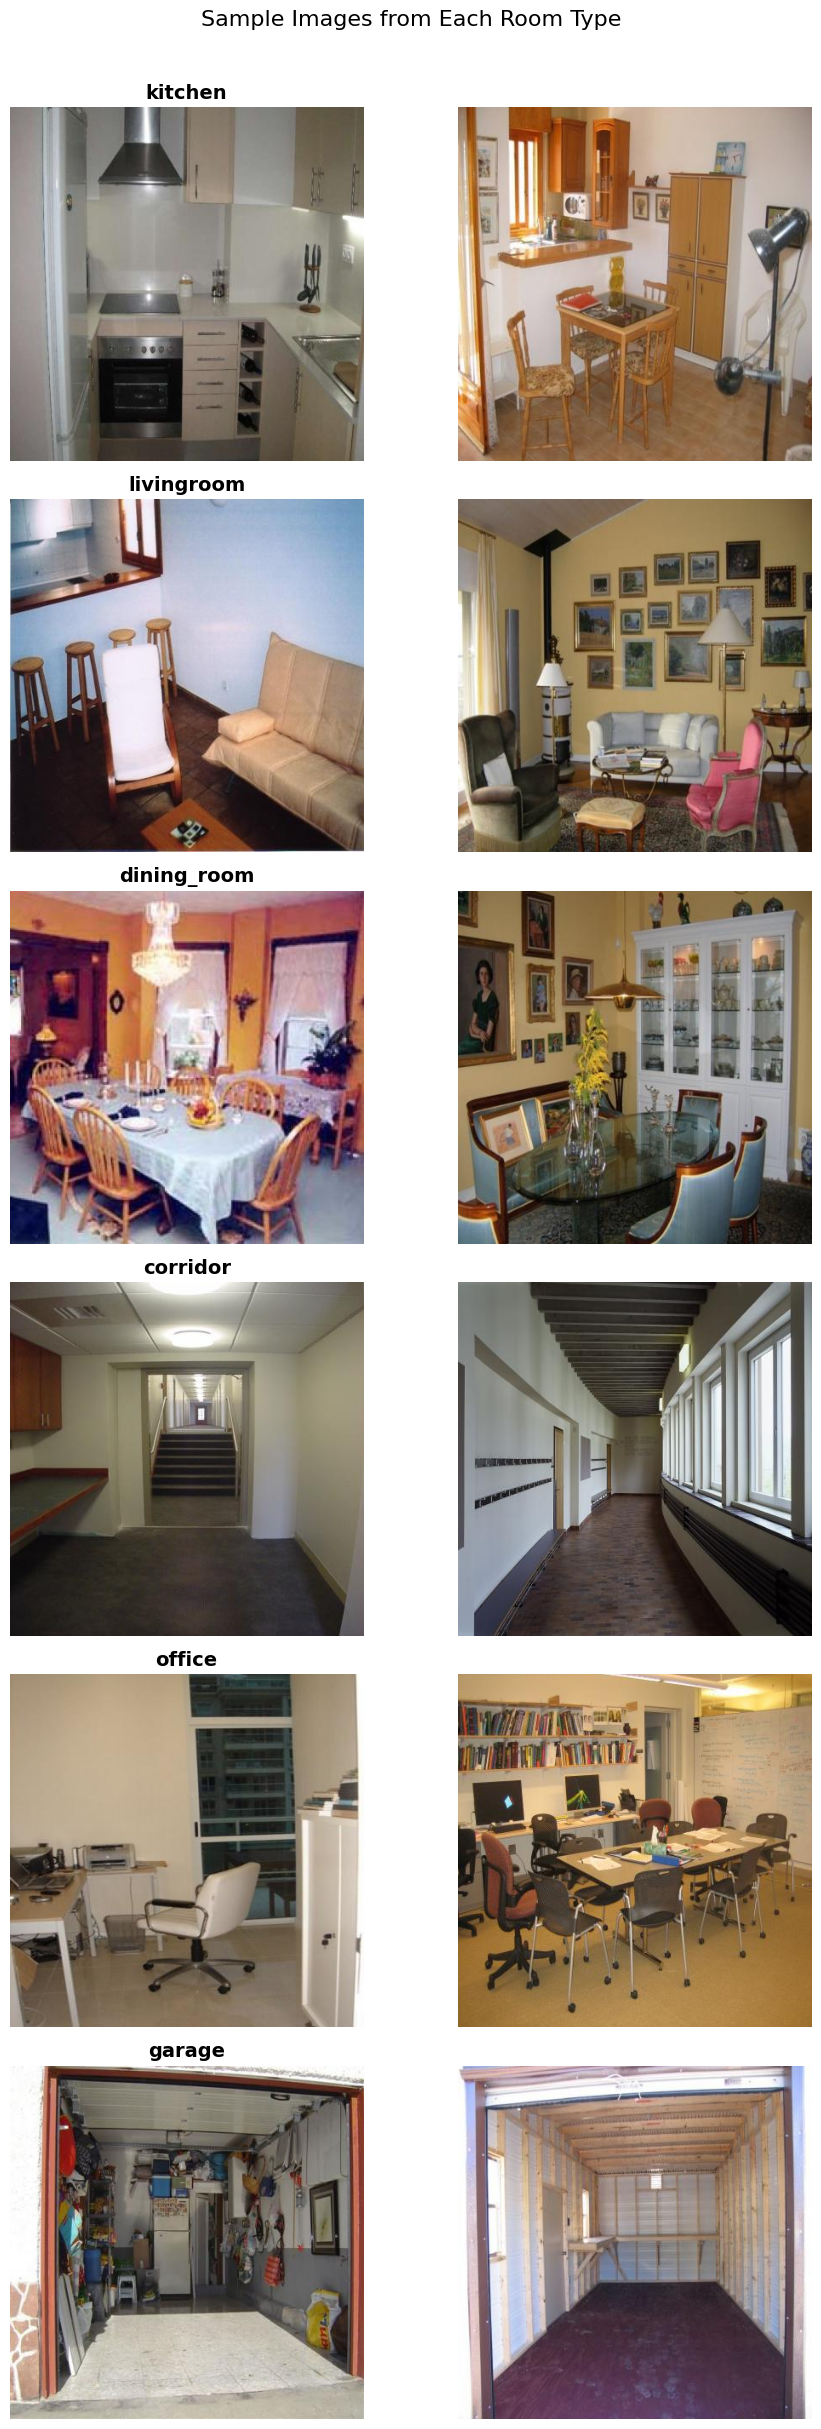

Done!


In [8]:
# Updated list matching only the categories actually present in your dataset
REAL_ESTATE_ROOMS = [
    'kitchen', 'livingroom', 'dining_room',
    'corridor', 'office', 'garage'
]

# Re-verify indices just for the categories that exist
room_indices = {name: idx for idx, name in enumerate(label_names) if name in REAL_ESTATE_ROOMS}

# 1. Pre-calculate exactly which row indices we need using the fast integer array
train_labels_list = list(train_filtered['label'])
indices_to_plot = []

for room_name in REAL_ESTATE_ROOMS:
    target_label = room_indices[room_name]
    # Grab the first two matching index positions
    matches = [i for i, lbl in enumerate(train_labels_list) if lbl == target_label][:2]
    indices_to_plot.append((room_name, matches))

# 2. Render the images using direct integer selection
fig, axes = plt.subplots(len(REAL_ESTATE_ROOMS), 2, figsize=(10, 4 * len(REAL_ESTATE_ROOMS)))

print("Rendering sample room images instantly...")
for row, (room_name, sample_indices) in enumerate(indices_to_plot):
    for col in range(2):
        ax = axes[row, col]
        if col < len(sample_indices):
            # Explicitly load just this single image from disk/RAM cache
            idx = sample_indices[col]
            img = train_filtered[idx]['image']
            ax.imshow(img)
            if col == 0:
                ax.set_title(f"{room_name}", fontsize=14, fontweight='bold')
        ax.axis('off')

plt.suptitle('Sample Images from Each Room Type', fontsize=16, y=1.01)
plt.tight_layout()
plt.show()
print("Done!")

In [9]:
from collections import Counter
import plotly.express as px

print("Calculating class distribution instantly...")
# Pull the entire column array directly from memory at once (no looping!)
train_labels_int = train_filtered['label']

# Convert the integers to their corresponding string names using our map
train_labels = [new_label_names[old_to_new[lbl]] for lbl in train_labels_int]
label_counts = Counter(train_labels)

dist_df = {'room_type': list(label_counts.keys()),
           'count': list(label_counts.values())}

fig_dist = px.bar(
    dist_df, x='room_type', y='count',
    title='Training Images per Room Type',
    labels={'count': 'Number of Images', 'room_type': 'Room Type'},
    color='room_type',
    text='count'
)
fig_dist.update_traces(textposition='outside')
fig_dist.update_layout(showlegend=False, height=450)
fig_dist.show()

print("Images per room type:")
for room, count in sorted(label_counts.items(), key=lambda x: -x[1]):
    print(f"  {room:<15}: {count} images")

Calculating class distribution instantly...


Images per room type:
  kitchen        : 650 images
  livingroom     : 645 images
  corridor       : 243 images
  dining_room    : 177 images
  office         : 101 images
  garage         : 74 images


---
## Step 4: Image Preprocessing

Raw images cannot be fed directly into a machine learning model.
We need to standardise them first.

Three preprocessing steps are required:

| Step | Why |
|---|---|
| Resize to 64x64 | All images must be the same size |
| Convert to RGB | Some images may be grayscale |
| Normalise to 0-1 | Pixel values 0-255 divided by 255.0 |

We use 64x64 for the baseline Logistic Regression model because it keeps
the feature count manageable (64 x 64 x 3 = 12,288 features per image).
For the transfer learning model in Step 6, we will use 128x128.

### Why do we remap the labels?

After filtering, our room types have scattered label numbers from the full
64 category dataset. For example:

```
garage     = label 24
kitchen    = label 34
livingroom = label 38
```

Machine learning models work better with sequential labels starting from 0:

```
garage     = label 2  (was 24)
kitchen    = label 3  (was 34)
livingroom = label 4  (was 38)
```

The `old_to_new` dictionary handles this conversion. Every time we process
an image, we translate its original label to the new sequential label.

### What the preprocessing function does

For each image in the dataset, the function performs three steps:

| Step | What happens | Why |
|---|---|---|
| 1. Resize | Change image to 64x64 pixels | All images must be the same size |
| 2. Convert to RGB | Ensure 3 colour channels | Some images may be grayscale (1 channel) |
| 3. Normalise | Divide pixel values by 255 | Scales numbers from 0-255 to 0.0-1.0 |

The result is a numpy array where each image is a grid of 64 x 64 x 3 = 12,288 numbers,
all between 0 and 1. This is the format that both Logistic Regression and CNNs expect.

In [10]:
# Update this list to match your active 6 categories
REAL_ESTATE_ROOMS = [
    'kitchen', 'livingroom', 'dining_room',
    'corridor', 'office', 'garage'
]

IMG_SIZE_BASELINE = 64   # for Logistic Regression
IMG_SIZE_TRANSFER = 128  # for transfer learning

# Re-verify mappings just in case
old_to_new = {old_idx: new_idx for new_idx, old_idx in enumerate(sorted(room_indices.values()))}

def preprocess_batch(batch, img_size):
    """
    Processes a batch of images using fast vectorized lists.
    """
    processed_images = []
    for img in batch['image']:
        # Convert and resize single PIL images in memory
        img_resized = img.convert('RGB').resize((img_size, img_size))
        processed_images.append(np.array(img_resized) / 255.0)

    processed_labels = [old_to_new[lbl] for lbl in batch['label']]

    return {"pixel_values": processed_images, "mapped_label": processed_labels}

print("Running fast batched preprocessing via Hugging Face engine...")
# .map with batched=True processes blocks of data simultaneously using optimized backends
train_mapped = train_filtered.map(lambda b: preprocess_batch(b, IMG_SIZE_BASELINE), batched=True, batch_size=250)
test_mapped  = test_filtered.map(lambda b: preprocess_batch(b, IMG_SIZE_BASELINE), batched=True, batch_size=250)

# Convert the mapped data columns straight into final NumPy arrays
X_train_img = np.array(train_mapped['pixel_values'])
y_train     = np.array(train_mapped['mapped_label'])

X_test_img  = np.array(test_mapped['pixel_values'])
y_test      = np.array(test_mapped['mapped_label'])

print(f"\nPreprocessing Complete!")
print(f"Training features shape : {X_train_img.shape}")
print(f"Test features shape     : {X_test_img.shape}")
print(f"Unique mapped labels    : {np.unique(y_train)} ({len(new_label_names)} classes)")

Running fast batched preprocessing via Hugging Face engine...


Map:   0%|          | 0/1890 [00:00<?, ? examples/s]

Map:   0%|          | 0/279 [00:00<?, ? examples/s]


Preprocessing Complete!
Training features shape : (1890, 64, 64, 3)
Test features shape     : (279, 64, 64, 3)
Unique mapped labels    : [0 1 2 3 4 5] (6 classes)


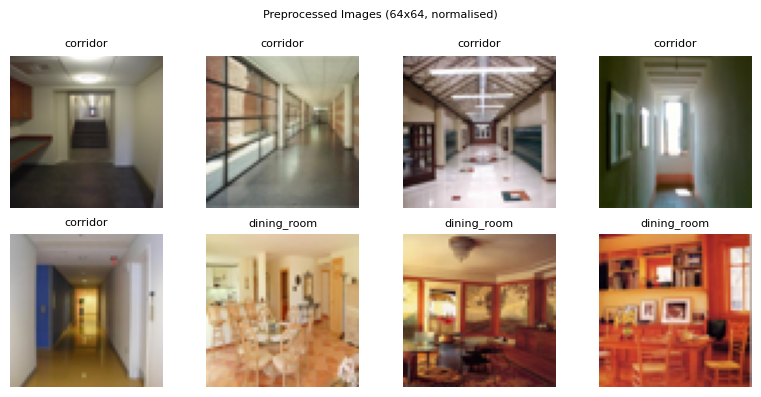

First image as numbers (top-left 5x5 pixels, red channel only):
[[0.29 0.31 0.33 0.35 0.35]
 [0.31 0.32 0.33 0.34 0.35]
 [0.31 0.31 0.32 0.34 0.34]
 [0.27 0.26 0.27 0.27 0.28]
 [0.37 0.31 0.25 0.25 0.27]]


In [11]:
# Visualise the preprocessing result
fig, axes = plt.subplots(2, 4, figsize=(8, 4))
for i, ax in enumerate(axes.flat):
    ax.imshow(X_train_img[i * 50])
    ax.set_title(new_label_names[y_train[i * 50]], fontsize=8)
    ax.axis('off')

plt.suptitle('Preprocessed Images (64x64, normalised)', fontsize=8)
plt.tight_layout()
plt.show()

# What one image looks like as numbers
print("First image as numbers (top-left 5x5 pixels, red channel only):")
print(X_train_img[0, :5, :5, 0].round(2))

---
## Step 5a: Baseline Model -- Logistic Regression on Raw Pixels

Our first model is deliberately simple. We flatten each 64x64x3 image
into a single row of 12,288 numbers and train a Logistic Regression
classifier, the same algorithm we used in Module 1 for text.

This establishes a baseline: if a simple model can already achieve
reasonable accuracy, that tells us the visual differences between
room types are strong. If accuracy is low, we know the problem
requires a more sophisticated approach.

### Why flatten?

Logistic Regression expects a flat 1D input, not a 3D image.
Flattening converts the image grid into a single row:

```
(64, 64, 3) image array
       |
   flatten
       |
(12288,) single row of numbers
```

This loses all spatial structure, the model does not know which
pixels are neighbours. That is the main limitation we address in Step 6.

In [12]:
# Flatten images: (n, 64, 64, 3) = (n, 12288)
X_train_flat = X_train_img.reshape(len(X_train_img), -1)
X_test_flat  = X_test_img.reshape(len(X_test_img), -1)

print(f"Flattened training shape: {X_train_flat.shape}")
print(f"Flattened test shape    : {X_test_flat.shape}")

# Train Logistic Regression
print("\nTraining Logistic Regression baseline")
baseline_model = LogisticRegression(max_iter=500, random_state=42)
baseline_model.fit(X_train_flat, y_train)

# Predict
y_pred_baseline = baseline_model.predict(X_test_flat)

# Evaluate
baseline_acc = accuracy_score(y_test, y_pred_baseline)
print(f"\nBaseline accuracy: {baseline_acc:.1%}")
print(f"\nDetailed results:")
print(classification_report(y_test, y_pred_baseline, target_names=new_label_names))

Flattened training shape: (1890, 12288)
Flattened test shape    : (279, 12288)

Training Logistic Regression baseline

Baseline accuracy: 29.4%

Detailed results:
              precision    recall  f1-score   support

    corridor       0.12      0.67      0.20         6
 dining_room       0.50      0.12      0.20        97
      garage       0.25      0.07      0.11        28
     kitchen       0.38      0.52      0.44        83
  livingroom       0.23      0.37      0.28        57
      office       0.00      0.00      0.00         8

    accuracy                           0.29       279
   macro avg       0.25      0.29      0.21       279
weighted avg       0.36      0.29      0.27       279



In [13]:
# Confusion matrix
cm_baseline = confusion_matrix(y_test, y_pred_baseline)

fig_cm = px.imshow(
    cm_baseline,
    labels=dict(x='Predicted', y='Actual', color='Count'),
    x=new_label_names, y=new_label_names,
    title='Confusion Matrix -- Logistic Regression Baseline',
    color_continuous_scale='Blues',
    text_auto=True
)
fig_cm.update_layout(width=600, height=550)
fig_cm.show()

# Discussion: which rooms does the model confuse most?
# Kitchen vs dining_room? Bedroom vs livingroom?
# Why might those pairs be difficult to distinguish?

### Reading the Confusion Matrix -- What the Model Gets Right and Wrong

The diagonal (top-left to bottom-right) shows correct predictions.
Everything off the diagonal shows mistakes.

**What the matrix reveals:**

Kitchen is the strongest category -- 43 out of 83 kitchen images were correctly
identified. The model learned that kitchens have a distinctive visual pattern
(cabinets, countertops, appliances).

Dining room is the weakest category -- only 12 correct out of 97 images.
Most dining room images were misclassified as livingroom (41) or kitchen (28).
This makes sense visually: a dining room with a table and chairs looks similar
to a livingroom with a sofa and coffee table, and an open-plan kitchen-diner
looks like a kitchen.

Livingroom is also heavily confused -- 21 correct but 23 classified as kitchen
and 7 as corridor. Open-plan apartments make it genuinely difficult to distinguish
livingroom from kitchen from dining room, even for a human.

Garage performs poorly -- only 2 correct out of 28 images. Most garage images
were misclassified as kitchen (13) or livingroom (7). This is surprising and
suggests the model is defaulting to the largest categories when unsure.

Office and corridor have very few correct predictions (0 and 4 respectively).
With small sample sizes, the model never sees enough examples to learn their
distinctive patterns.

**The key insight:**

The model struggles most when rooms share visual elements. An open kitchen
with a dining table, a livingroom with a kitchenette, a corridor that opens
into a livingroom, these are genuinely ambiguous even in real photographs.
This is why the baseline Logistic Regression approach is limited: it treats
every pixel independently and cannot understand that "cabinets near a stove"
means kitchen while "cabinets near a desk" means office.

The CNN and MobileNetV2 models in the next steps address this by learning
spatial relationships between visual elements, not just individual pixel values.

## Step 5b: Simple CNN: Learning Spatial Patterns from Scratch

Logistic Regression flattens the image into a single row of numbers
and treats every pixel independently. It has no concept of "the pixel
next to this one" -- it cannot see edges, shapes, or textures.

A Convolutional Neural Network (CNN) fixes this. Instead of looking
at individual pixels, it scans the image with small windows (called
filters or kernels) that detect local patterns:

Layer 1 filters detect edges -- vertical lines, horizontal lines, diagonals.
Layer 2 filters combine edges into shapes -- corners, curves, rectangles.
Layer 3 filters combine shapes into objects -- a sink, a bed, a stove.

Each convolutional layer builds on the patterns found by the previous one,
creating an increasingly abstract understanding of the image:

Raw pixels → edges → shapes → objects → classification

This is fundamentally different from Logistic Regression:

| | Logistic Regression | Simple CNN |
|---|---|---|
| Sees spatial relationships | No -- pixels are independent | Yes -- scans with local windows |
| Learns features automatically | No -- uses raw pixel values | Yes -- learns edges, shapes, objects |
| Number of parameters | 12,288 x 6 = 73,728 weights (plus 6 biases) | 204,230 (conv filters + dense layers) |
| Training time | Seconds | 2-3 minutes |

We build this CNN from scratch with 3 convolutional layers.
It uses the same 64x64 images as the baseline -- no pre-trained knowledge,
no external model. Everything it learns comes purely from our training images.
This is the honest middle ground between a simple classifier and transfer learning.

 Displaying feature extractions for a: CORRIDOR



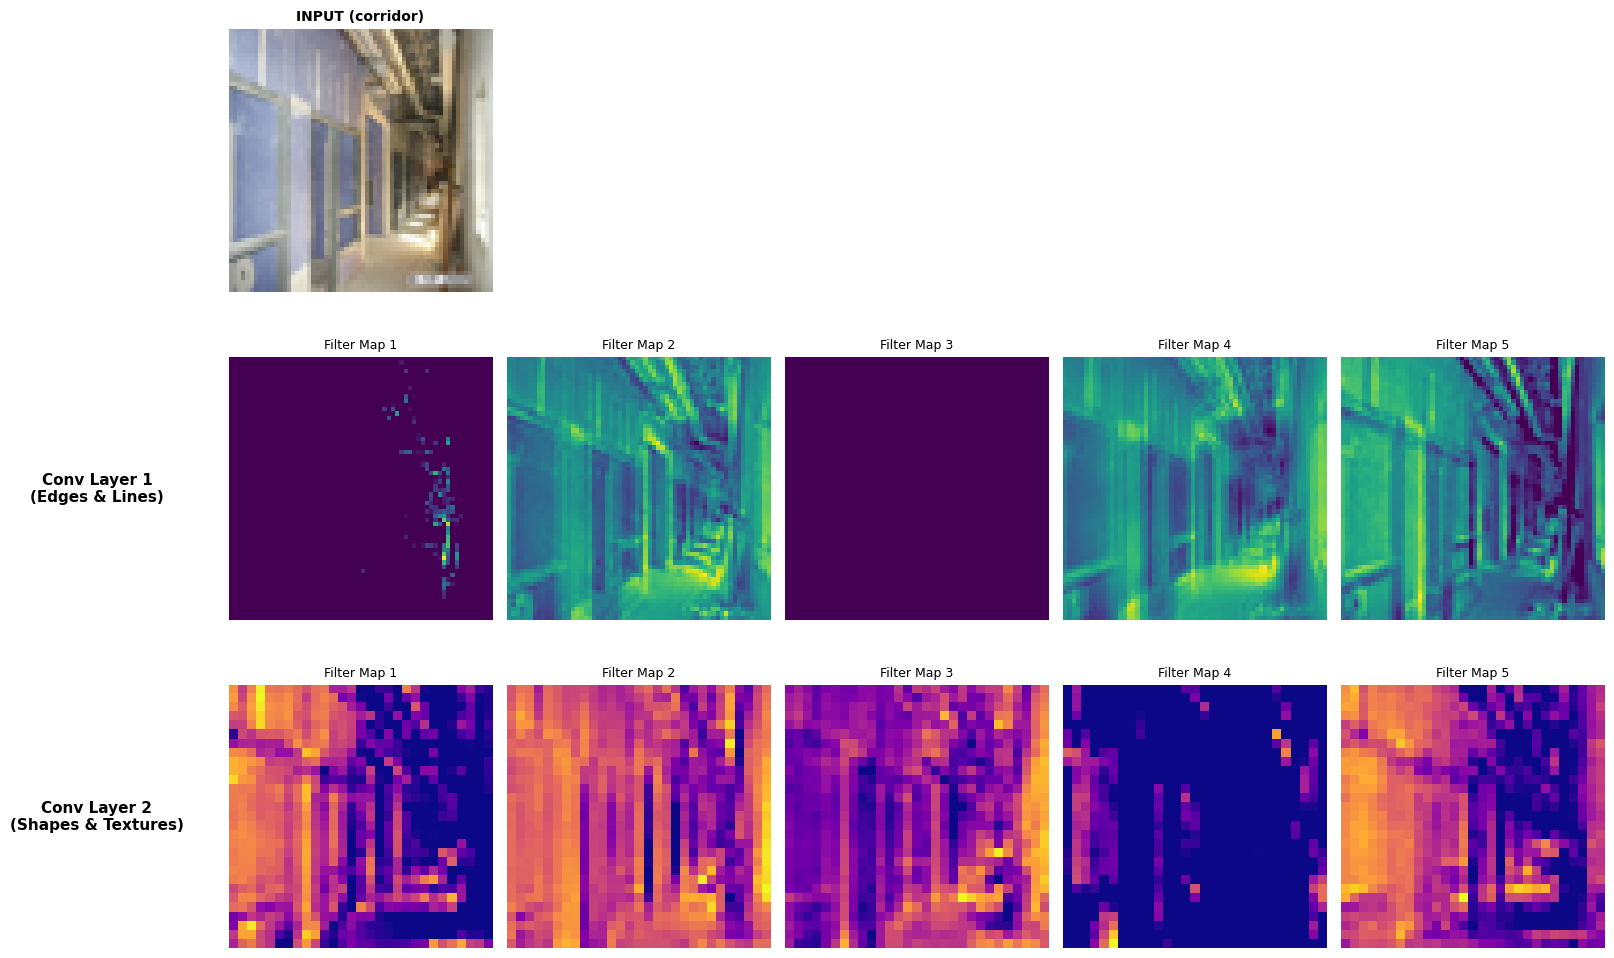

In [16]:
import tensorflow as tf
from tensorflow.keras import layers, models
import matplotlib.pyplot as plt

# 1. Select an image from our test set to pass through the neural network
sample_index = 0
sample_image = test_filtered[sample_index]['image']
sample_label = test_filtered[sample_index]['label']
true_room_name = new_label_names[old_to_new[sample_label]]

# Preprocess to match standard model dimensions (64x64)
img_resized = sample_image.resize((64, 64))
img_array = np.array(img_resized) / 255.0  # Normalise pixels to [0, 1]
input_batch = np.expand_dims(img_array, axis=0)  # Shape becomes (1, 64, 64, 3)

# 2. Define a transparent CNN model mimicking our Architecture
np.random.seed(42)
tf.random.set_seed(42)

# Refactor to use the Keras Functional API for robust input/output definition
model_input = layers.Input(shape=(64, 64, 3), name='model_input_tensor')
x = layers.Conv2D(32, (3, 3), activation='relu', name='Conv_Layer_1')(model_input)
x = layers.MaxPooling2D((2, 2), name='MaxPool_Layer_1')(x)
x = layers.Conv2D(64, (3, 3), activation='relu', name='Conv_Layer_2')(x)
model_output = layers.MaxPooling2D((2, 2), name='MaxPool_Layer_2')(x)

cnn_model = models.Model(inputs=model_input, outputs=model_output, name='feature_extractor_cnn')

# The previous dummy call is no longer needed as model_input is explicitly defined
# _ = cnn_model(tf.zeros((1, 64, 64, 3))) # Dummy call to build the graph (now redundant but harmless)

# 3. Extract outputs from the specific target layers
# (This line on 33/34 will now run perfectly without throwing an AttributeError!)
layer_outputs = [cnn_model.get_layer(name).output for name in ['Conv_Layer_1', 'MaxPool_Layer_1', 'Conv_Layer_2', 'MaxPool_Layer_2']]
activation_model = models.Model(inputs=cnn_model.input, outputs=layer_outputs)

# Run our real-estate image through the model to get the feature matrices
activations = activation_model.predict(input_batch, verbose=0)

# 4. Plotting the results for student visualization
print(f" Displaying feature extractions for a: {true_room_name.upper()}\n")

fig, axes = plt.subplots(3, 5, figsize=(16, 10))

# Top Row: Original Input Reference
axes[0, 0].imshow(img_resized)
axes[0, 0].set_title(f"INPUT ({true_room_name})", fontsize=10, fontweight='bold')
axes[0, 0].axis('off')

# Turn off unused layout boxes on the top row to keep it perfectly clean
for j in range(1, 5):
    axes[0, j].axis('off')

# Middle Row: Conv Layer 1 (Extracting low-level features like edges & lines)
layer_1_maps = activations[0]
axes[1, 0].text(-0.5, 0.5, "Conv Layer 1\n(Edges & Lines)", va='center', ha='center', fontsize=11, fontweight='bold', transform=axes[1, 0].transAxes)
for i in range(5):
    axes[1, i].imshow(layer_1_maps[0, :, :, i], cmap='viridis')
    axes[1, i].set_title(f"Filter Map {i+1}", fontsize=9)
    axes[1, i].axis('off')

# Bottom Row: Conv Layer 2 (Combining lines into complex geometric shapes)
layer_2_maps = activations[2]
axes[2, 0].text(-0.5, 0.5, "Conv Layer 2\n(Shapes & Textures)", va='center', ha='center', fontsize=11, fontweight='bold', transform=axes[2, 0].transAxes)
for i in range(5):
    axes[2, i].imshow(layer_2_maps[0, :, :, i], cmap='plasma')
    axes[2, i].set_title(f"Filter Map {i+1}", fontsize=9)
    axes[2, i].axis('off')

plt.tight_layout()
plt.show()

### What we've visualized: A look inside the CNN

The image you just saw is a direct visualization of how a Convolutional Neural Network (CNN) processes an image. We observed:

*   **Input Image (Top Row):** This is the original image fed into the CNN, such as a photo of a 'CORRIDOR'.
*   **Conv Layer 1 (Middle Row - Edges & Lines):** After the first convolutional layer, the image is broken down into various 'feature maps'. Each map highlights different low-level patterns like edges, lines, and corners present in the input.
*   **Conv Layer 2 (Bottom Row - Shapes & Textures):** The second convolutional layer takes the features from the first layer and combines them. Here, the feature maps start to show more complex patterns, forming basic shapes and textures by combining the detected edges and lines.

This visualization demonstrates that the CNN learns progressively more complex visual features at each layer, moving from simple elements like lines to more abstract shapes and textures.

In [17]:
# The brain of our simple CNN, telling it how to process images step-by-step
# How to prepare for learning.

NUM_CLASSES = len(new_label_names)

from tensorflow.keras import layers, models
import tensorflow as tf

# Build a simple CNN from scratch -- 3 convolutional layers
simple_cnn = models.Sequential([

    # Layer 1: detect edges and simple patterns
    # 32 filters, each 3x3 pixels, scanning across the image
    layers.Conv2D(32, (3, 3), activation='relu', input_shape=(64, 64, 3)),
    layers.MaxPooling2D((2, 2)),  # shrink the image by half

    # Layer 2: detect shapes built from edges
    layers.Conv2D(64, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),

    # Layer 3: detect complex patterns built from shapes
    layers.Conv2D(64, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),

    # Convert 3D feature maps into a 1D vector
    layers.Flatten(),

    # Classification head
    layers.Dense(64, activation='relu'),
    layers.Dropout(0.3),          # prevents overfitting
    layers.Dense(NUM_CLASSES, activation='softmax')
])

simple_cnn.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

# Show model architecture
simple_cnn.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 62, 62, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 31, 31, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 29, 29, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 14, 14, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 12, 12, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 6, 6, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 2304)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │       147,520 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 6)              │           390 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 204,230 (797.77 KB)

 Trainable params: 204,230 (797.77 KB)

 Non-trainable params: 0 (0.00 B)

In [18]:
# Train the CNN from scratch

print("Training simple CNN from scratch...")
print("No pre-trained knowledge, everything is learned from our images.\n")

history_cnn = simple_cnn.fit(
    X_train_img, y_train,
    validation_data=(X_test_img, y_test),
    epochs=10,
    batch_size=32,
    verbose=1
)

# Evaluate
y_pred_cnn = simple_cnn.predict(X_test_img).argmax(axis=1)
cnn_acc = accuracy_score(y_test, y_pred_cnn)

print(f"\nSimple CNN accuracy: {cnn_acc:.1%}")
print(f"Logistic Regression was: {baseline_acc:.1%}")
print(f"Improvement: +{cnn_acc - baseline_acc:.1%} absolute")
print(f"\nThe CNN performs better because it understands spatial structure.")
print(f"But it learned everything from only our training images --")
print(f"Step 6 will show what happens when we start with knowledge")
print(f"from 14 million images instead of learning from scratch.")

Training simple CNN from scratch...
No pre-trained knowledge, everything is learned from our images.

Epoch 1/10
60/60 ━━━━━━━━━━━━━━━━━━━━ 18s 269ms/step - accuracy: 0.3413 - loss: 1.5511 - val_accuracy: 0.2043 - val_loss: 1.9130
Epoch 2/10
60/60 ━━━━━━━━━━━━━━━━━━━━ 12s 206ms/step - accuracy: 0.3683 - loss: 1.5246 - val_accuracy: 0.2581 - val_loss: 1.9474
Epoch 3/10
60/60 ━━━━━━━━━━━━━━━━━━━━ 12s 203ms/step - accuracy: 0.3921 - loss: 1.4785 - val_accuracy: 0.2867 - val_loss: 1.8874
Epoch 4/10
60/60 ━━━━━━━━━━━━━━━━━━━━ 11s 188ms/step - accuracy: 0.4254 - loss: 1.4224 - val_accuracy: 0.2903 - val_loss: 1.7269
Epoch 5/10
60/60 ━━━━━━━━━━━━━━━━━━━━ 11s 188ms/step - accuracy: 0.4672 - loss: 1.3478 - val_accuracy: 0.3441 - val_loss: 1.7391
Epoch 6/10
60/60 ━━━━━━━━━━━━━━━━━━━━ 21s 201ms/step - accuracy: 0.5085 - loss: 1.2706 - val_accuracy: 0.3548 - val_loss: 1.7258
Epoch 7/10
60/60 ━━━━━━━━━━━━━━━━━━━━ 12s 206ms/step - accuracy: 0.5280 - loss: 1.2001 - val_accuracy: 0.3620 - val_loss: 1.

### Training and Evaluating Our Simple CNN

In this step, we've trained our `simple_cnn` model from scratch, meaning it started with no prior knowledge and learned entirely from our filtered image dataset. Here's what happened:

*   **Training (`simple_cnn.fit(...)`):** The model was fed the training images (`X_train_img`) and their corresponding labels (`y_train`). It iteratively adjusted its internal parameters (the filters in the convolutional layers and weights in the dense layers) to better predict the room types.
*   **Validation (`validation_data=(X_test_img, y_test)`):** During training, the model also periodically tested its performance on unseen test images. This helps us monitor if the model is learning general patterns or just memorizing the training data.
*   **Evaluation (`simple_cnn.predict(...)` and `accuracy_score`):** After training, we made final predictions on the test set and calculated the accuracy. This tells us how often the model correctly identified the room type for images it had never seen before.
*   **Comparison:** We then compared this CNN's accuracy with our earlier Logistic Regression baseline. The results show that the CNN, by understanding spatial relationships within images, significantly outperforms the baseline model. However, it still has room for improvement, especially since it started learning from zero. The next step will explore how starting with 'pre-trained knowledge' can boost performance even further.

A note on method: to keep this module simple, we watch the test set during training.
In a real project you would hold out a separate validation set for that,
and use the test set only once at the very end.


---
## Step 6: Transfer Learning with MobileNetV2

### What is Transfer Learning?

Training an image classifier from scratch requires millions of images
and days of GPU computation. Transfer learning takes a shortcut:
we start with a model that has already learned to see.

MobileNetV2 was trained by Google on 14 million images (ImageNet).
It already knows how to detect edges, textures, shapes, and objects.
We reuse that knowledge and only train a small new layer on top
to classify our 6 room types.

Think of it this way:

```
MobileNetV2 (pre-trained, frozen)
    Already knows: edges, textures, shapes, objects
              |
    Our new layer (trained on room images)
    Learns: these shapes and textures = kitchen,
            those shapes and textures = garage
              |
    Prediction: kitchen / livingroom / garage / ...
```

This is the standard approach in the industry.
Companies do not train from scratch, they transfer.

### Why do we multiply by 255 and then preprocess again?

This looks confusing but there is a simple reason.

In Step 4, we normalised all pixel values to the range 0.0 to 1.0
by dividing by 255. This is correct for our baseline model and simple CNN.

However, MobileNetV2 was trained by Google using a DIFFERENT normalisation.
Google's `preprocess_input` function expects pixel values in the original
0-255 range and applies its own scaling internally.

So we need to:

```
Step 1: Our images are currently 0.0 to 1.0 (from Step 4)
Step 2: Multiply by 255 to get back to 0-255 range
Step 3: Pass through preprocess_input() which applies Google's specific scaling
```

This is a common source of bugs in transfer learning. If you forget this step,
the model receives numbers in the wrong range and accuracy drops dramatically.

We also resize images to 128x128 instead of 64x64 because MobileNetV2
was designed for larger images and extracts more useful features at higher resolution.

In [19]:
import tensorflow as tf
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input
from tensorflow.keras import layers, models

# Preprocess images at 128x128 for MobileNetV2
print("Preprocessing images for transfer learning (128x128)...")

# Reuse the preprocess_batch function defined earlier
train_tf_mapped = train_filtered.map(lambda b: preprocess_batch(b, IMG_SIZE_TRANSFER), batched=True, batch_size=250)
test_tf_mapped  = test_filtered.map(lambda b: preprocess_batch(b, IMG_SIZE_TRANSFER), batched=True, batch_size=250)

X_train_tf = np.array(train_tf_mapped['pixel_values'])
X_test_tf  = np.array(test_tf_mapped['pixel_values'])

# MobileNetV2 expects a specific input format
# The `preprocess_batch` already normalizes to 0-1, so we reverse it before MobileNetV2's preprocess_input
X_train_tf = preprocess_input(X_train_tf * 255)
X_test_tf  = preprocess_input(X_test_tf * 255)

print(f"Transfer learning input shape: {X_train_tf.shape}")

NUM_CLASSES = len(new_label_names)
print(f"Number of classes: {NUM_CLASSES}")

Preprocessing images for transfer learning (128x128)...


Map:   0%|          | 0/1890 [00:00<?, ? examples/s]

Map:   0%|          | 0/279 [00:00<?, ? examples/s]

Transfer learning input shape: (1890, 128, 128, 3)
Number of classes: 6


### Understanding the transfer learning code, term by term

The next cell contains several terms that may be unfamiliar.
Here is what each one means:

| Code | What it means in plain language |
|---|---|
| `weights='imagenet'` | Load the knowledge from 14 million ImageNet images |
| `include_top=False` | Remove Google's original classification layer (it classifies 1000 objects -- we need only 6 rooms) |
| `base_model.trainable = False` | Lock the pre-trained knowledge -- do not change it during our training |
| `GlobalAveragePooling2D()` | Compress the feature maps into a single summary vector (instead of flattening, which would create too many parameters) |
| `Dropout(0.3)` | During training, randomly ignore 30% of neurons each batch, this prevents memorisation |
| `Dense(64, activation='relu')` | A layer of 64 neurons that learns to combine MobileNet's features into room-relevant patterns |
| `Dense(NUM_CLASSES, activation='softmax')` | Final layer with one neuron per room type, outputting probabilities |
| `sparse_categorical_crossentropy` | The loss function for classification when labels are integers (0, 1, 2, ...) rather than one-hot encoded |

The key idea: we are NOT training MobileNetV2 from scratch.
We are only training the small classification head on top.
MobileNetV2 has 2.2 million parameters -- we freeze all of them.
Our new head has roughly 80,000 parameters -- only these get trained.
This is why transfer learning is fast: about 82,000 trainable parameters instead of 2,340,000.

In [20]:
# Load the pre-trained MobileNetV2 model
# include_top=False removes the final classification layer
# We replace it with our own layer for 6 room types

base_model = MobileNetV2(
    weights='imagenet',
    include_top=False,
    input_shape=(IMG_SIZE_TRANSFER, IMG_SIZE_TRANSFER, 3)
)

# Freeze the base model -- we do NOT retrain its 2.2 million parameters
base_model.trainable = False

# Build our classification head
model = models.Sequential([
    base_model,
    layers.GlobalAveragePooling2D(),   # converts feature maps to a single vector
    layers.Dropout(0.3),               # prevents overfitting
    layers.Dense(64, activation='relu'),
    layers.Dense(NUM_CLASSES, activation='softmax')  # output: probability per room type
])

model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

model.summary()
print(f"\nTotal parameters     : {model.count_params():,}")
print(f"Trainable parameters : {sum(p.numpy().size for p in model.trainable_weights):,}")
print(f"Frozen parameters    : {sum(p.numpy().size for p in model.non_trainable_weights):,}")

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ mobilenetv2_1.00_128            │ (None, 4, 4, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 64)             │        81,984 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 6)              │           390 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,340,358 (8.93 MB)

 Trainable params: 82,374 (321.77 KB)

 Non-trainable params: 2,257,984 (8.61 MB)


Total parameters     : 2,340,358
Trainable parameters : 82,374
Frozen parameters    : 2,257,984


In [21]:
# Train only our new classification head (takes 2-5 minutes)
print("Training transfer learning model...")
print("Only the final layers are being trained.")
print("The pre-trained MobileNetV2 backbone is frozen.\n")

history = model.fit(
    X_train_tf, y_train,
    validation_data=(X_test_tf, y_test),
    epochs=10,
    batch_size=32,
    verbose=1
)

Training transfer learning model...
Only the final layers are being trained.
The pre-trained MobileNetV2 backbone is frozen.

Epoch 1/10
60/60 ━━━━━━━━━━━━━━━━━━━━ 38s 529ms/step - accuracy: 0.7026 - loss: 0.8438 - val_accuracy: 0.6774 - val_loss: 0.8073
Epoch 2/10
60/60 ━━━━━━━━━━━━━━━━━━━━ 30s 502ms/step - accuracy: 0.8307 - loss: 0.4651 - val_accuracy: 0.6989 - val_loss: 0.8190
Epoch 3/10
60/60 ━━━━━━━━━━━━━━━━━━━━ 29s 473ms/step - accuracy: 0.8608 - loss: 0.3819 - val_accuracy: 0.7061 - val_loss: 0.8907
Epoch 4/10
60/60 ━━━━━━━━━━━━━━━━━━━━ 40s 462ms/step - accuracy: 0.8751 - loss: 0.3391 - val_accuracy: 0.7276 - val_loss: 0.8403
Epoch 5/10
60/60 ━━━━━━━━━━━━━━━━━━━━ 29s 492ms/step - accuracy: 0.8884 - loss: 0.2864 - val_accuracy: 0.7312 - val_loss: 0.8617
Epoch 6/10
60/60 ━━━━━━━━━━━━━━━━━━━━ 43s 524ms/step - accuracy: 0.9127 - loss: 0.2434 - val_accuracy: 0.7061 - val_loss: 0.9832
Epoch 7/10
60/60 ━━━━━━━━━━━━━━━━━━━━ 30s 498ms/step - accuracy: 0.9122 - loss: 0.2363 - val_accurac

### How to read a training history chart

The next cell plots two lines:

- **Training accuracy** (blue): how well the model performs on images it is learning from
- **Test accuracy** (green): how well the model performs on images it has never seen

Three possible patterns:

```
Pattern 1: GOOD (both lines rise together)
   Training:  ------>  rising
   Test:      ------>  rising alongside
   Meaning:   The model is learning real patterns that work on new images.

Pattern 2: OVERFITTING (training rises, test flattens or drops)
   Training:  ------>  rising
   Test:      ---->  flattens or drops
   Meaning:   The model is memorising training images instead of learning
              general patterns. It performs well on images it has seen
              but poorly on new ones.

Pattern 3: UNDERFITTING (both lines stay low)
   Training:  --->  stays low
   Test:      --->  stays low
   Meaning:   The model is not learning anything useful.
              Usually means: not enough data, too few epochs,
              or the model is too simple for the task.
```

For our model, we want to see Pattern 1 or a slight gap between the lines
(training slightly higher than test is normal and expected).

In [22]:
# Plot training history
fig_history = go.Figure()
fig_history.add_trace(go.Scatter(
    y=history.history['accuracy'], name='Training accuracy',
    mode='lines+markers', line=dict(color='#3498db')
))
fig_history.add_trace(go.Scatter(
    y=history.history['val_accuracy'], name='Test accuracy',
    mode='lines+markers', line=dict(color='#2ecc71')
))
fig_history.update_layout(
    title='Training Progress -- Accuracy per Epoch',
    xaxis_title='Epoch',
    yaxis_title='Accuracy',
    height=400
)
fig_history.show()

# If training accuracy rises but test accuracy flattens or drops,
# the model is overfitting -- it memorised the training images
# instead of learning general patterns.

In [23]:
# Evaluate transfer learning model
y_pred_transfer = model.predict(X_test_tf).argmax(axis=1)

transfer_acc = accuracy_score(y_test, y_pred_transfer)
print(f"Transfer learning accuracy: {transfer_acc:.1%}")
print(f"\nDetailed results:")
print(classification_report(y_test, y_pred_transfer, target_names=new_label_names))

9/9 ━━━━━━━━━━━━━━━━━━━━ 6s 532ms/step
Transfer learning accuracy: 74.2%

Detailed results:
              precision    recall  f1-score   support

    corridor       0.50      1.00      0.67         6
 dining_room       0.90      0.63      0.74        97
      garage       0.90      0.64      0.75        28
     kitchen       0.83      0.87      0.85        83
  livingroom       0.53      0.79      0.63        57
      office       0.71      0.62      0.67         8

    accuracy                           0.74       279
   macro avg       0.73      0.76      0.72       279
weighted avg       0.79      0.74      0.75       279



### Evaluating the Transfer Learning Model

This evaluation shows the impact of transfer learning:

*   **Overall accuracy**: The MobileNetV2 model reached **74.2%** on the test set, compared with 29.4% for the Logistic Regression baseline and 41.6% for the simple CNN trained from scratch. Starting from knowledge learned on ImageNet makes a large difference.

*   **Performance per class (precision, recall, F1-score)**:
    *   **Kitchen** is the strongest class (precision 0.83, recall 0.87, F1 0.85).
    *   **Dining room** and **garage** have high precision (0.90) but lower recall (about 0.63): when the model says "dining room" it is usually right, but it misses more than a third of them.
    *   **Livingroom** shows the opposite pattern (recall 0.79, precision 0.53): many other rooms are wrongly labelled as livingroom.
    *   **Corridor** and **office** have only 6 and 8 test images, so a single image changes their scores a lot. Do not over-interpret them.

Your exact numbers will differ slightly each time you train, because neural network training is not fully deterministic.


---
## Step 7: Compare All Three Models

We built three models with very different approaches:

| | Logistic Regression | Simple CNN | MobileNetV2 Transfer |
|---|---|---|---|
| Input | Flattened 64x64 pixels | 64x64 image | 128x128 image |
| Spatial awareness | None -- treats pixels as independent | Yes -- learned from scratch | Yes -- pre-trained |
| Parameters trained | 73,734 | 204,230 | 82,374 (new head only) |
| Pre-trained knowledge | None | None | ImageNet |
| Training time | Seconds | A few minutes | A few minutes |


In [24]:
# Three-way comparison
comparison = {
    'Model': [
        'Logistic Regression (baseline)',
        'Simple CNN (from scratch)',
        'MobileNetV2 (transfer learning)'
    ],
    'Accuracy': [baseline_acc, cnn_acc, transfer_acc]
}

fig_compare = px.bar(
    comparison, x='Model', y='Accuracy',
    title='Model Comparison -- Three Levels of Computer Vision',
    text=[f'{a:.1%}' for a in comparison['Accuracy']],
    color='Model',
    color_discrete_map={
        'Logistic Regression (baseline)': '#e74c3c',
        'Simple CNN (from scratch)': '#f39c12',
        'MobileNetV2 (transfer learning)': '#2ecc71'
    }
)
fig_compare.update_traces(textposition='outside', textfont_size=14)
fig_compare.update_layout(
    showlegend=False, height=500,
    yaxis_range=[0, max(comparison['Accuracy']) * 1.25]
)
fig_compare.show()

print("Accuracy progression:")
print(f"  Logistic Regression : {baseline_acc:.1%}  (no spatial awareness)")
print(f"  Simple CNN          : {cnn_acc:.1%}  (learned from our data only)")
print(f"  MobileNetV2         : {transfer_acc:.1%}  (pre-trained on 14M images)")
print(f"\nBaseline to CNN       : +{cnn_acc - baseline_acc:.1%}  (spatial awareness helps)")
print(f"CNN to MobileNetV2    : +{transfer_acc - cnn_acc:.1%}  (pre-trained knowledge helps)")
print(f"Baseline to MobileNetV2: +{transfer_acc - baseline_acc:.1%}  (total improvement)")

Accuracy progression:
  Logistic Regression : 29.4%  (no spatial awareness)
  Simple CNN          : 41.6%  (learned from our data only)
  MobileNetV2         : 74.2%  (pre-trained on 14M images)

Baseline to CNN       : +12.2%  (spatial awareness helps)
CNN to MobileNetV2    : +32.6%  (pre-trained knowledge helps)
Baseline to MobileNetV2: +44.8%  (total improvement)


In [25]:
# Confusion matrix for transfer learning model
cm_transfer = confusion_matrix(y_test, y_pred_transfer)

fig_cm2 = px.imshow(
    cm_transfer,
    labels=dict(x='Predicted', y='Actual', color='Count'),
    x=new_label_names, y=new_label_names,
    title='Confusion Matrix -- MobileNetV2 Transfer Learning',
    color_continuous_scale='Greens',
    text_auto=True
)
fig_cm2.update_layout(width=600, height=550)
fig_cm2.show()

---
## Step 8: Test on Individual Images

The model is trained. Now test it on individual images to see
predictions with confidence scores.

### How the prediction function works step by step

When you give the model a new image it has never seen, the function does this:

```
Your photo (any size, any format)
       |
  1. Convert to RGB and resize to 128x128
       |
  2. Convert to numpy array and normalise (divide by 255)
       |
  3. Apply Google's preprocess_input scaling
       |
  4. Add a batch dimension with expand_dims
     The model expects input shape (batch_size, 128, 128, 3)
     A single image is (128, 128, 3) -- we add a 1 at the front
     to make it (1, 128, 128, 3) -- a batch of one image
       |
  5. model.predict() runs the image through MobileNetV2 + our head
     Returns an array of probabilities, one per room type
     Example: [0.05, 0.08, 0.04, 0.75, 0.06, 0.02]
       |
  6. argmax() finds which position has the highest probability
     Position 3 = 0.75 = highest = kitchen
       |
  Result: 'kitchen' with 75% confidence
```

The `expand_dims` step is the one that confuses most beginners.
It does not change the image data at all -- it just wraps it in an
extra bracket so the model receives it in the correct format.

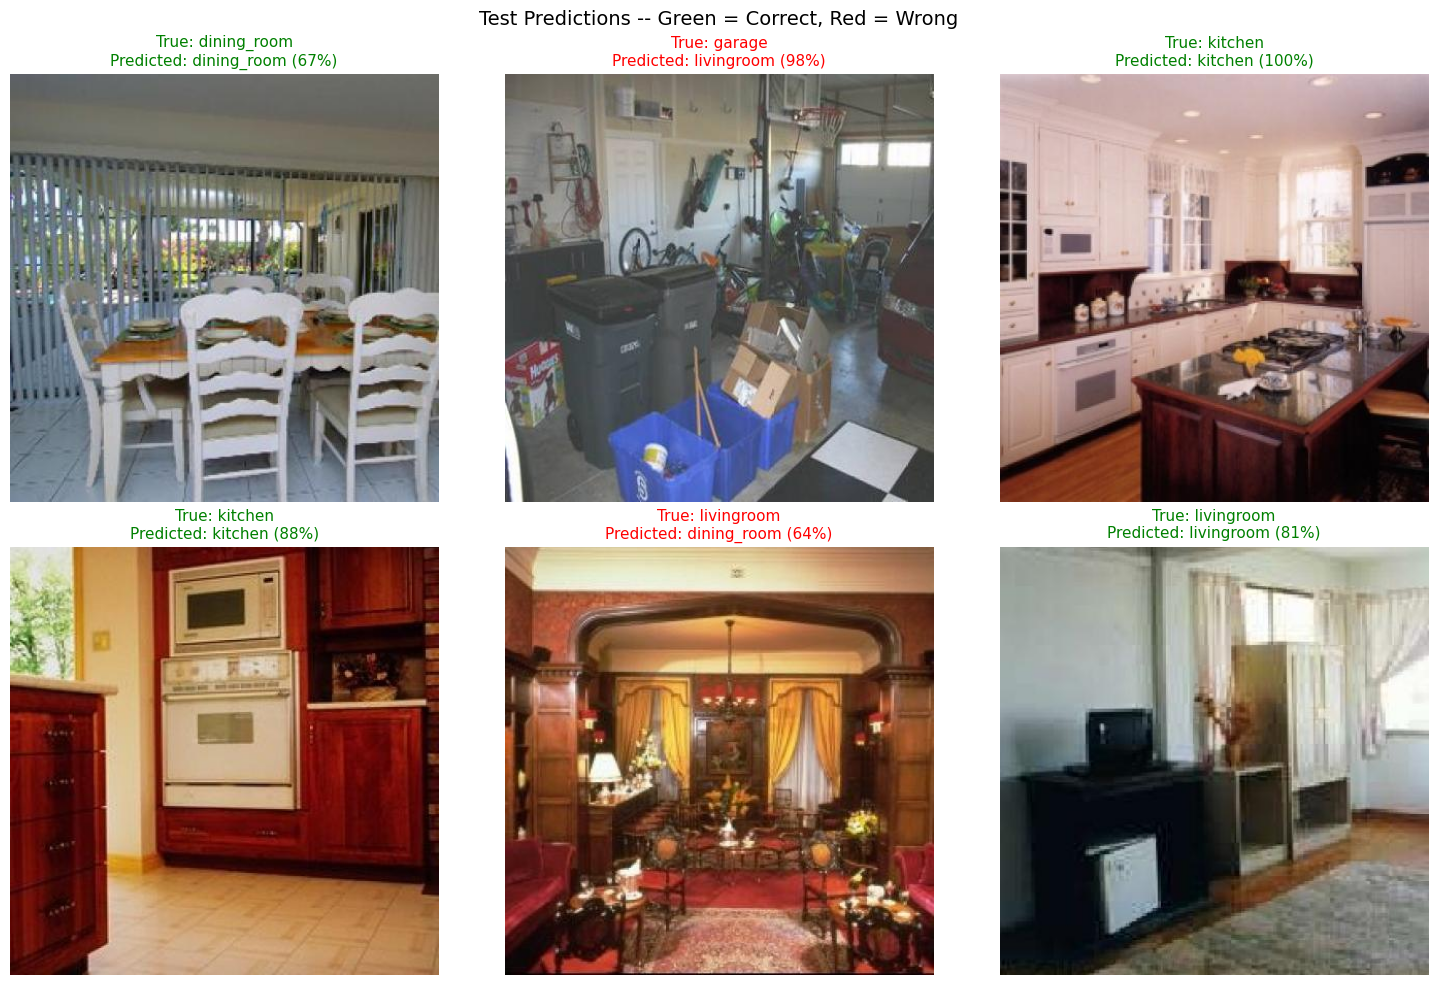

In [26]:
def predict_room(image, model, img_size=IMG_SIZE_TRANSFER):
    """
    Predicts the room type for a single PIL image.
    Returns the predicted class and confidence scores.
    """
    img_resized = image.convert('RGB').resize((img_size, img_size))
    img_array   = np.array(img_resized) / 255.0
    img_input   = preprocess_input(np.expand_dims(img_array * 255, axis=0))

    probs      = model.predict(img_input, verbose=0)[0]
    pred_class = new_label_names[np.argmax(probs)]
    confidence = np.max(probs)

    return pred_class, confidence, probs

# Test on 6 random images from the test set
np.random.seed(42)
sample_indices = np.random.choice(len(test_filtered), 6, replace=False)

fig, axes = plt.subplots(2, 3, figsize=(15, 10))
for idx, ax in zip(sample_indices, axes.flat):
    example   = test_filtered[int(idx)]
    true_name = label_names[example['label']]
    pred_name, conf, _ = predict_room(example['image'], model)

    correct = pred_name == true_name
    color   = 'green' if correct else 'red'

    ax.imshow(example['image'])
    ax.set_title(f"True: {true_name}\nPredicted: {pred_name} ({conf:.0%})",
                 color=color, fontsize=11)
    ax.axis('off')

plt.suptitle('Test Predictions -- Green = Correct, Red = Wrong', fontsize=14)
plt.tight_layout()
plt.show()

---
## Step 9: AI Workflow Integration -- Save and Deploy

Just like in Modules 1 and 2, we save the trained model so it can
be loaded and used in any Python application without retraining.

For the baseline sklearn model, we use joblib.
For the Keras model, we use the native SavedModel format.

In [27]:
# Save the baseline sklearn pipeline
baseline_pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('classifier', LogisticRegression(max_iter=500, random_state=42))
])
baseline_pipeline.fit(X_train_flat, y_train)
joblib.dump(baseline_pipeline, 'room_classifier_baseline.pkl')
print("Baseline pipeline saved: room_classifier_baseline.pkl")

# Save the Keras transfer learning model
model.save('room_classifier_mobilenet.keras')
print("Transfer learning model saved: room_classifier_mobilenet.keras")

# Reload and test
loaded_model = tf.keras.models.load_model('room_classifier_mobilenet.keras')
test_example = test_filtered[0]
pred, conf, _ = predict_room(test_example['image'], loaded_model)
print(f"\nLoaded model prediction: {pred} ({conf:.0%})")
print(f"\nThis is how a deployed property classification API works:")
print(f"  1. Property platform uploads a photo")
print(f"  2. API loads the saved model")
print(f"  3. Model predicts: kitchen / bedroom / bathroom / ...")
print(f"  4. Photo is automatically tagged and sorted")

Baseline pipeline saved: room_classifier_baseline.pkl
Transfer learning model saved: room_classifier_mobilenet.keras

Loaded model prediction: corridor (93%)

This is how a deployed property classification API works:
  1. Property platform uploads a photo
  2. API loads the saved model
  3. Model predicts: kitchen / bedroom / bathroom / ...
  4. Photo is automatically tagged and sorted


---
## Your Turn -- Exercises

---

### Exercise 1 -- Interpret the Confusion Matrix

Look at the MobileNetV2 confusion matrix from Step 7 and answer:

1. Which room type has the highest accuracy?
2. Which two room types does the model confuse most often?
3. Why might kitchen and dining_room be difficult to distinguish visually?

---

### Exercise 2 -- Increase Image Resolution

Change IMG_SIZE_TRANSFER from 128 to 224 (the standard MobileNetV2 input size).
Retrain the model. Does accuracy improve?

Fill in the table:

| Resolution | Accuracy | Training Time |
|---|---|---|
| 64x64 (baseline) | ? | ? |
| 128x128 | ? | ? |
| 224x224 | ? | ? |

In [ ]:
# TODO: Change IMG_SIZE_TRANSFER to 224
# TODO: Re-run Steps 6 and 7
# TODO: Compare accuracy and training time


### Exercise 3: Add More Room Types

Add 'closet' and 'nursery' to the REAL_ESTATE_ROOMS list.
Retrain both models. Does adding categories help or hurt accuracy?

> Hint: More classes with less data per class makes the problem harder.

---

### Exercise 4: Test on Your Own Photos

Upload a photo from your phone to Google Colab and run the model on it.

```python
from google.colab import files
uploaded = files.upload()
for filename in uploaded.keys():
    img = Image.open(filename)
    pred, conf, probs = predict_room(img, model)
    print(f"{filename}: {pred} ({conf:.0%})")
    plt.imshow(img)
    plt.title(f"Predicted: {pred} ({conf:.0%})")
    plt.axis('off')
    plt.show()
```

---

## Key Takeaways

| Concept | What You Learned |
|---|---|
| Images as numbers | A photo is a 3D array of pixel values (height x width x 3 RGB channels) |
| Preprocessing | Resize, convert to RGB, normalise to 0-1 before training |
| Flattening | Convert 3D image to 1D vector for traditional ML models |
| Baseline model | Logistic Regression and CNNs |
| Transfer learning | Reuse a pre-trained model's knowledge instead of training from scratch |
| MobileNetV2 | Google's efficient image model trained on 14 million images |
| Confusion matrix | Shows which room types the model confuses with each other |
| Model saving | sklearn Pipeline with joblib, Keras model with .keras format |